In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import *
from sklearn.preprocessing import MinMaxScaler

import torch
from torch import nn, optim
from torch.utils.data import TensorDataset , DataLoader

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32):
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle= True)

    return train_loader, x_val_tensor, y_val_tensor

In [4]:
def train(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0

    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    tr_loss /= num_batches
    return tr_loss.item()

In [5]:
def evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        x, y = x_val_tensor.to(device), y_val_tensor.to(device)
        pred = model(x)
        eval_loss = loss_fn(pred, y).item()
    return eval_loss, pred

In [6]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label='train_err', marker='.')
    plt.plot(epochs, val_loss_list, label='val_err', marker='.')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

In [7]:
import requests
from io import BytesIO
import certifi

In [8]:
path = "https://bit.ly/titanic_simple_csv"
response = requests.get(path, verify= certifi.where(), timeout=15)
response.raise_for_status()
data = pd.read_csv(BytesIO(response.content))
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,7.2500,Southampton
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,71.2833,Cherbourg
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,7.9250,Southampton
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,53.1000,Southampton
4,5,0,3,"Allen, Mr. William Henry",male,35.0,8.0500,Southampton


In [9]:
target = 'Survived'
feature = ['Sex', 'Age', 'Fare']
x = data.loc[:, feature]
y = data.loc[:, target]

In [10]:
# 가변수화
# 성별(Sex)는 범주형 데이터이기 때문에 특징으로 사용하려면 가변수화 필요함

x = pd.get_dummies(x, columns= ['Sex'], drop_first= True)
x.head()

,Age,Fare,Sex_male
0,22.0,7.2500,True
1,38.0,71.2833,False
2,26.0,7.9250,False
3,35.0,53.1000,False
4,35.0,8.0500,True


In [16]:
# 데이터 분할 후 데이터로더 생성
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.3)

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

y_train = y_train.values
y_val = y_val.values

train_loader, x_val_tensor, y_val_tensor = make_DataSet(x_train, x_val, y_train, y_val, 32)

# 첫번째 배치만 로딩
for x, y in train_loader:
    print(f"Shape of x [rows, columns]: {x.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of x [rows, columns]: torch.Size([32, 3])
Shape of y: torch.Size([32, 1]) torch.float32


In [12]:
# 모델 설계
LR = 1e-2
EPOCH = 50

n_feature = x.shape[1]
model = nn.Sequential(nn.Linear(n_feature, 1),
                      nn.Sigmoid()
        ).to(device)


In [13]:
loss_fn = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr= LR)

In [14]:
tr_loss_list, val_loss_list = [], []

for ep in range(EPOCH):
    tr_loss = train(train_loader, model, loss_fn, optimizer, device)
    val_loss, _ = evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device)
    tr_loss_list.append(tr_loss)
    val_loss_list.append(val_loss)
    print(f'Epoch: {ep+1}, Train Loss: {tr_loss:.4f}, Eval Loss: {val_loss:.4f}')

Epoch: 1, Train Loss: 0.6852, Eval Loss: 0.6520
Epoch: 2, Train Loss: 0.6405, Eval Loss: 0.6114
Epoch: 3, Train Loss: 0.6207, Eval Loss: 0.5890
Epoch: 4, Train Loss: 0.6081, Eval Loss: 0.5762
Epoch: 5, Train Loss: 0.5970, Eval Loss: 0.5667
Epoch: 6, Train Loss: 0.5902, Eval Loss: 0.5587
Epoch: 7, Train Loss: 0.5839, Eval Loss: 0.5516
Epoch: 8, Train Loss: 0.5774, Eval Loss: 0.5451
Epoch: 9, Train Loss: 0.5711, Eval Loss: 0.5383
Epoch: 10, Train Loss: 0.5634, Eval Loss: 0.5329
Epoch: 11, Train Loss: 0.5633, Eval Loss: 0.5280
Epoch: 12, Train Loss: 0.5565, Eval Loss: 0.5233
Epoch: 13, Train Loss: 0.5533, Eval Loss: 0.5189
Epoch: 14, Train Loss: 0.5474, Eval Loss: 0.5161
Epoch: 15, Train Loss: 0.5460, Eval Loss: 0.5133
Epoch: 16, Train Loss: 0.5432, Eval Loss: 0.5090
Epoch: 17, Train Loss: 0.5419, Eval Loss: 0.5064
Epoch: 18, Train Loss: 0.5343, Eval Loss: 0.5042
Epoch: 19, Train Loss: 0.5366, Eval Loss: 0.5014
Epoch: 20, Train Loss: 0.5319, Eval Loss: 0.5004
Epoch: 21, Train Loss: 0.5336

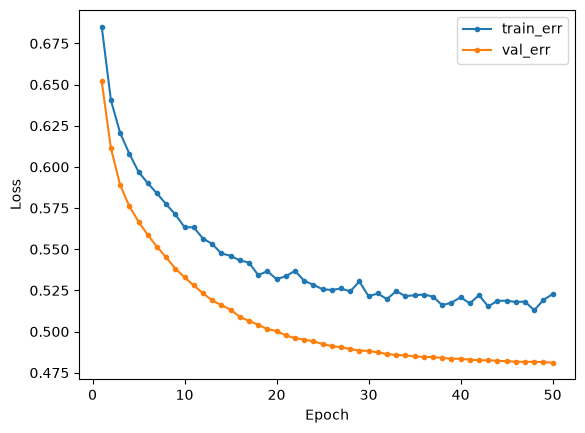

In [15]:
learning_curve(tr_loss_list, val_loss_list)

In [18]:
# 검증 평가
_, pred = evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device)
print(pred.numpy()[:5])

pred = np.where(pred.numpy() > .5, 1, 0)
print(pred[:5])

[[0.1839931 ]
 [0.18667217]
 [0.67520696]
 [0.1879173 ]
 [0.18763673]]
[[0]
 [0]
 [1]
 [0]
 [0]]


In [20]:
# 성능 평가
print(confusion_matrix(y_val_tensor.numpy(), pred))

print(classification_report(y_val_tensor.numpy(), pred))

[[99 18]
 [24 73]]
              precision    recall  f1-score   support

         0.0       0.80      0.85      0.82       117
         1.0       0.80      0.75      0.78        97

    accuracy                           0.80       214
   macro avg       0.80      0.80      0.80       214
weighted avg       0.80      0.80      0.80       214

